<p style="text-align: right; margin: 0; line-height: 0;"><img width="100px" height="auto" src="../../.admin/img/eth_logo.png"></p>

<h1 style="text-align: center;">02 Data Communication</h1>
<hr>


## **4. Digital Modulation**

<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693
  
</div>




### 4.1 Introduction

A sequence of bits cannot travel through the air on its own. A transmitter must turn the data into a physical signal, and a receiver must distinguish the possible signal states despite noise and interference. **Digital modulation** provides this connection between information and a waveform. The choice of modulation determines how many bits each signal state can represent and how difficult those states are to distinguish at the receiver.

The previous notebook introduced channel coding, which adds redundancy to help recover data affected by errors. Modulation takes the resulting channel-coded bits, groups them into **symbols**, and represents each symbol with a waveform suitable for transmission:

$$\text{channel-coded bits} \rightarrow \text{modulation symbols} \rightarrow \text{physical waveform}.$$

Some wired links transmit baseband pulses directly. Wireless and other passband systems place the signal around a carrier frequency within an allocated band. Changing the carrier's amplitude, frequency, or phase makes it possible to represent different symbols. This notebook first explores these changes individually, then combines them in quadrature amplitude modulation. The final experiments examine the trade-off between carrying more bits per symbol and maintaining reliable reception.


### 4.2 Digital Signals and Modulation Basics

A sinusoidal carrier can be written as

$$
x(t) = A \sin(2\pi f_c t + \theta)
$$

where $A$ is the amplitude, $f_c$ is the carrier frequency, and $\theta$ is the phase shift. The controls below vary these parameters independently. Amplitude changes the height of the waveform, frequency changes the number of cycles per second, and phase shifts the position within a cycle.

Digital modulation uses a set of defined carrier states to represent symbols. **Amplitude-shift keying (ASK)** selects an amplitude, **frequency-shift keying (FSK)** selects a frequency, and **phase-shift keying (PSK)** selects a phase. The binary examples in the following sections use two states, with one state representing bit 0 and the other bit 1. Later, **quadrature amplitude modulation (QAM)** combines amplitude and phase to provide a larger set of states.

In the binary modulation equations, $s[n]$ denotes the bit in interval $n$, and $T_b$ is the duration of that interval. Each bit therefore controls the waveform from $nT_b$ to $(n+1)T_b$. The examples use cosine carriers; sine and cosine differ only by a fixed phase shift.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider, Text, Dropdown

def plot_sine(A=1.0, f=5.0, phi=0.0):
    # Continuous-time signal
    t_cont = np.linspace(0, 1, 1000)
    s_cont = A * np.sin(2 * np.pi * f * t_cont + phi)

    
    plt.figure(figsize=(8, 4))
    plt.plot(t_cont, s_cont, label='Continuous-time sine')
    plt.title(f'Sinusoid: A={A:.2f}, f={f:.2f} Hz, φ={phi:.2f} rad')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(True)
    plt.ylim(-5, 5)
    plt.show()

# Create interactive sliders
interact(
    plot_sine,
    A=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, description='Amplitude'),
    f=FloatSlider(value=5.0, min=0.1, max=50.0, step=0.1, description='Freq (Hz)'),
    phi=FloatSlider(value=0.0, min=0.0, max=2*np.pi, step=0.1, description='Phase (rad)'),
)


interactive(children=(FloatSlider(value=1.0, description='Amplitude', max=5.0, min=0.1), FloatSlider(value=5.0…

<function __main__.plot_sine(A=1.0, f=5.0, phi=0.0)>

#### 4.2.1 Amplitude-Shift Keying (ASK)

Use two amplitudes $A_0$ and $A_1$ to represent bits 0 and 1, respectively. The **A0 (bit 0)** slider changes the carrier amplitude during intervals containing a 0; **A1 (bit 1)** changes it during intervals containing a 1. The lower plot shows the original bits and remains unchanged when either amplitude is adjusted.

The upper plot uses a fixed vertical scale so that amplitude changes remain visible. If both amplitudes are equal, the waveform no longer distinguishes between 0 and 1.

$$
x_{\mathrm{ASK}}(t)
=
\begin{cases}
A_0 \,\cos\bigl(2\pi f_c\,t\bigr), & s[n] = 0,\\[6pt]
A_1 \,\cos\bigl(2\pi f_c\,t\bigr), & s[n] = 1,
\end{cases}
\quad
t \in [nT_b,\,(n+1)T_b).
$$


In [2]:
def ask_modulation(bits, fc, A0, A1, Tb=0.1, fs=10000):
    """
    Simple ASK modulator with fixed Tb and fs.
    
    bits : list of 0/1
    fc   : carrier frequency (Hz)
    A0   : amplitude for bit 0
    A1   : amplitude for bit 1
    
    Returns:
    t, x : time vector and ASK signal
    """
    t = np.arange(0, len(bits)*Tb, 1/fs)
    x = np.zeros_like(t)
    for i, b in enumerate(bits): # iterate over bits
        idx = (t >= i*Tb) & (t < (i+1)*Tb) # find indices for current bit
        
        amp = A1 if b == 1 else A0
        x[idx] = amp * np.cos(2*np.pi*fc*t[idx])
    return t, x

In [ ]:
def plot_ask(seq='0101101', A0=0.5, A1=1.0):
    fc = 50  # carrier frequency
    if not seq or any(bit not in '01' for bit in seq):
        print("Enter at least one bit using only 0 and 1, for example 0101101.")
        return
    bits = [int(b) for b in seq]
    Tb = 0.1  # bit duration
    t, ask_sig = ask_modulation(bits, fc, A0, A1)
    # align digital waveform
    bit_idx = np.floor(t/Tb).astype(int)
    bit_idx[bit_idx >= len(bits)] = len(bits)-1
    digital = np.array(bits)[bit_idx]

    fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axs[0].plot(t, ask_sig, color='orange', label='ASK Signal')
    axs[0].set_title('ASK Modulation')
    axs[0].set_ylabel('Amplitude')
    axs[0].set_ylim(-2.1, 2.1)  # Fixed scale for comparing slider settings.
    axs[0].grid(True)
    axs[0].legend()

    axs[1].step(t, digital, where='post', color='blue', label='Digital Data')
    axs[1].set_title('Digital Signal')
    axs[1].set_xlabel('Time (s)')
    axs[1].set_ylabel('Level')
    axs[1].set_ylim(-0.1, 1.1)
    axs[1].grid(True)
    axs[1].legend()

    plt.tight_layout()
    plt.show()

    print("Interactive ASK Modulation:")

interact(
    plot_ask,
    seq=Text(value='0101101', description='Bits'),
    A0=FloatSlider(value=0.5, min=0.1, max=2.0, step=0.1, description='A0 (bit 0)'),
    A1=FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, description='A1 (bit 1)'),
)

interactive(children=(Text(value='0101101', description='Bits'), FloatSlider(value=0.5, description='A0 (bit 0…

<function __main__.plot_ask(seq='0101101', A0=0.5, A1=1.0)>

#### 4.2.2 Frequency-Shift Keying (FSK)

Binary FSK represents bit 0 with frequency $f_0$ and bit 1 with frequency $f_1$, while keeping the amplitude fixed. In the upper plot, the waveform oscillates more rapidly during intervals assigned the higher frequency. The lower plot provides the corresponding bit sequence.

Adjust the two frequency controls and compare intervals containing 0 and 1. If the frequencies are equal, both bits produce the same waveform, so frequency can no longer distinguish them.

$$
x_{\mathrm{FSK}}(t)
=
A \,\cos\bigl(2\pi f_{s[n]}\,t\bigr),
\quad
f_{s[n]} =
\begin{cases}
f_0, & s[n] = 0,\\[4pt]
f_1, & s[n] = 1,
\end{cases}
$$

$$
t \in [nT_b,\,(n+1)T_b).
$$


In [4]:
def fsk_modulation(bits, f0, f1, Tb=0.1, fs=10000):
    """
    Simple FSK modulator with fixed Tb and fs.
    
    bits : list of 0/1
    f0   : frequency for bit 0
    f1   : frequency for bit 1
    
    Returns:
    t, x : time vector and FSK signal
    """
    t = np.arange(0, len(bits)*Tb, 1/fs)
    x = np.zeros_like(t)
    for i, b in enumerate(bits): # iterate over bits
        idx = (t >= i*Tb) & (t < (i+1)*Tb) # find indices for current bit
        
        # Set frequency based on bit value
        freq = f1 if b == 1 else f0
        
        x[idx] = np.cos(2*np.pi*freq*t[idx])
    return t, x

In [ ]:
## Plotting FSK Modulation

def plot_fsk(seq='0101101', f0=20, f1=60):
    if not seq or any(bit not in '01' for bit in seq):
        print("Enter at least one bit using only 0 and 1, for example 0101101.")
        return
    bits = [int(b) for b in seq]
    Tb=0.1
    t, fsk_sig = fsk_modulation(bits, f0, f1)
    # align digital waveform
    bit_idx = np.floor(t/Tb).astype(int)
    bit_idx[bit_idx >= len(bits)] = len(bits)-1
    digital = np.array(bits)[bit_idx]

    fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axs[0].plot(t, fsk_sig, color='green', label='FSK Signal')
    axs[0].set_title('FSK Modulation')
    axs[0].set_ylabel('Amplitude')
    axs[0].grid(True)
    axs[0].legend()

    axs[1].step(t, digital, where='post', color='blue', label='Digital Data')
    axs[1].set_title('Digital Signal')
    axs[1].set_xlabel('Time (s)')
    axs[1].set_ylabel('Level')
    axs[1].set_ylim(-0.1, 1.1)
    axs[1].grid(True)
    axs[1].legend()

    plt.tight_layout()
    plt.show()

print("\nInteractive FSK Modulation:")
interact(
    plot_fsk,
    seq=Text(value='0101101', description='Bits'),
    f0=FloatSlider(value=40, min=1, max=200, step=1, description='f0 (Hz)'),
    f1=FloatSlider(value=60, min=1, max=200, step=1, description='f1 (Hz)')
)



Interactive FSK Modulation:


interactive(children=(Text(value='0101101', description='Bits'), FloatSlider(value=40.0, description='f0 (Hz)'…

<function __main__.plot_fsk(seq='0101101', f0=20, f1=60)>

#### 4.2.3 Phase-Shift Keying (PSK)

The binary form of PSK, **BPSK**, uses two phases separated by $\pi$ radians, or 180 degrees. The carrier frequency and amplitude remain fixed while the bit value selects its phase. In this example, bit 0 uses the reference cosine and bit 1 uses its negative.

Compare the carrier with the digital waveform below it, particularly at boundaries where the bit changes. Changing the amplitude or carrier frequency affects both bit states; the information is carried by their phase relationship.

$$
x_{\mathrm{BPSK}}(t)
=
A \,\cos\bigl(2\pi f_c\,t + \pi\,s[n]\bigr)
=
\begin{cases}
+\,A\cos(2\pi f_c t), & s[n]=0,\\[4pt]
-\,A\cos(2\pi f_c t), & s[n]=1,
\end{cases}
\quad t\in[nT_b,\,(n+1)T_b).
$$


In [6]:
def bpsk_modulation(bits, fc, A, Tb=0.1, fs=10000):
    """
    Simple BPSK modulator with fixed Tb and fs.
    
    bits : list of 0/1
    fc   : carrier frequency (Hz)
    A    : amplitude for both bits
    
    Returns:
    t, x : time vector and BPSK signal
    """
    t = np.arange(0, len(bits)*Tb, 1/fs)
    x = np.zeros_like(t)
    for i, b in enumerate(bits): # iterate over bits
        idx = (t >= i*Tb) & (t < (i+1)*Tb) # find indices for current bit
        
        # Set phase based on bit value (standard BPSK: 0 for bit 0, π for bit 1)
        phase = 0 if b == 0 else np.pi
        
        x[idx] = A * np.cos(2*np.pi*fc*t[idx] + phase)
    return t, x

In [ ]:
## Plotting BPSK Modulation

def plot_bpsk(seq='0101101', A=1.0, fc=50):

    """Interactive BPSK modulator with digital waveform below."""
    Tb = 0.1
    if not seq or any(bit not in '01' for bit in seq):
        print("Enter at least one bit using only 0 and 1, for example 0101101.")
        return
    bits = [int(b) for b in seq]
    t, sig = bpsk_modulation(bits, fc, A)
    # align digital waveform
    bit_idx = np.floor(t/Tb).astype(int)
    bit_idx[bit_idx >= len(bits)] = len(bits) - 1
    digital = np.array(bits)[bit_idx]

    fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    # Top: BPSK signal
    axs[0].plot(t, sig, color='purple', label='BPSK Signal')
    axs[0].set_title('BPSK Modulation')
    axs[0].set_ylabel('Amplitude')
    axs[0].grid(True)
    axs[0].legend()

    # Bottom: digital data
    axs[1].step(t, digital, where='post', color='blue', label='Digital Data')
    axs[1].set_title('Digital Signal')
    axs[1].set_xlabel('Time (s)')
    axs[1].set_ylabel('Level')
    axs[1].set_ylim(-0.1, 1.1)
    axs[1].grid(True)
    axs[1].legend()

    plt.tight_layout()
    plt.show()

print("Interactive BPSK Modulation:")
interact(
    plot_bpsk,
    seq=Text(value='0101101', description='Bits'),
    A=FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, description='Amplitude'),
    fc=IntSlider(value=50, min=1, max=200, step=1, description='fc (Hz)')
)


Interactive BPSK Modulation:


interactive(children=(Text(value='0101101', description='Bits'), FloatSlider(value=1.0, description='Amplitude…

<function __main__.plot_bpsk(seq='0101101', A=1.0, fc=50)>

### 4.3 Quadrature Amplitude Modulation (QAM)

The binary ASK, FSK, and BPSK examples each transmit one bit per symbol. To represent several bits with one symbol, the transmitter needs more than two distinguishable states. **Quadrature amplitude modulation (QAM)** provides these states by combining two carrier components that are 90 degrees apart in phase. Their weights can change from symbol to symbol while the carrier frequency remains fixed.

A **constellation diagram** represents each possible symbol as a point in the complex plane. The horizontal coordinate gives the **in-phase (I)** component, and the vertical coordinate gives the **quadrature (Q)** component. Together, these coordinates determine the carrier's amplitude and phase: the distance from the origin corresponds to amplitude, and the angle from the positive horizontal axis corresponds to phase. Selecting a constellation point therefore selects a complete signal state.

#### 4.3.1 Examples of Constellations

**Quadrature phase-shift keying (QPSK)** and square 4-QAM have equivalent four-point constellations up to rotation and scaling. Four possible states can represent the four combinations of two bits. A 16-QAM constellation has sixteen points and carries four bits per symbol, while 64-QAM has sixty-four points and carries six bits per symbol. In general,

$$
\text{Bits per symbol} = \log_2(M)
$$

where $M$ is the number of constellation points, also called the modulation order.

Use the constellation control below to compare the available modulation orders. The example normalizes each constellation to the same average power. As more points are added, the separation between neighbouring states decreases, making them harder to distinguish in the presence of noise.


In [ ]:
def qam_points(M: int):
    """
    Return constellation points for QPSK (M=4) or square QAM (M in {4,16,64,256, 1024}).
    Points are normalized to unit average power.
    """

    m_side = int(np.sqrt(M))
    if m_side * m_side != M:
        raise ValueError("M must be a perfect square (e.g., 4, 16, 64, 256).")

    # Square grid: e.g., for 16-QAM -> levels [-3, -1, +1, +3]
    levels = np.arange(-(m_side - 1), m_side, 2)
    x, y = np.meshgrid(levels, levels[::-1])  # reverse y so top is positive imag
    pts = (x + 1j * y).reshape(-1)
    pts = pts / np.sqrt(np.mean(np.abs(pts)**2))
    return pts


# --- Plot 4-QAM and 16-QAM side by side ---
def plot_qam_constellation(M=4):
    pts = qam_points(M)
    plt.figure(figsize=(6, 6))
    plt.scatter(pts.real, pts.imag, s=60)
    plt.axhline(0, color='black', linewidth=0.5)
    plt.axvline(0, color='black', linewidth=0.5)
    lim = 1.2 * np.max(np.abs([pts.real.max(), pts.real.min(),
                               pts.imag.max(), pts.imag.min()]))
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("Real (cosine)")
    plt.ylabel("Imag (sine)")
    plt.title(f"Constellation (M = {M})")
    plt.grid(True)
    plt.show()

interact(
    plot_qam_constellation,
    M=Dropdown(
        options=[4, 16, 64, 256, 1024],
        value=4,
        description='QAM Level'
    )
)


interactive(children=(Dropdown(description='QAM Level', options=(4, 16, 64, 256, 1024), value=4), Output()), _…

<function __main__.plot_qam_constellation(M=4)>

#### 4.3.2 Symbol Mapping

A constellation defines the available signal states, but the transmitter and receiver must also agree on which bits each state represents. This assignment is called **symbol mapping**. The diagrams below label each QPSK point with two bits and each 16-QAM point with four bits.

The choice of labels affects how symbol errors translate into bit errors. If neighbouring points have labels that differ in several positions, a small disturbance that pushes a received symbol into a neighbouring decision region can change several decoded bits. **Gray coding** assigns labels so that adjacent points differ by only one bit. An error to a nearest neighbour then usually produces a single bit error. This reduces the number of affected bits without changing the constellation size or the number of bits carried by each symbol.

Compare the labels on horizontally and vertically adjacent points in the two diagrams. The arrangement illustrates how the mapping limits the consequences of a small detection error.


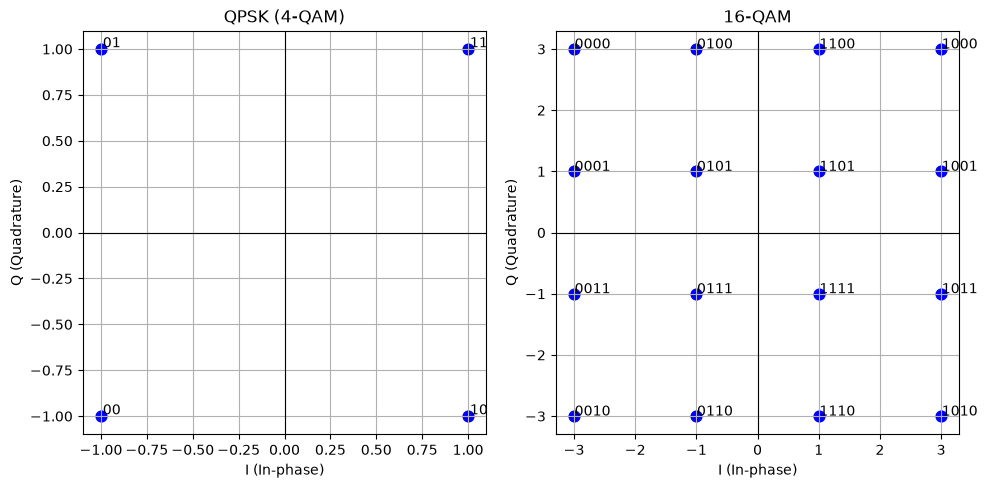

In [9]:
# --- QPSK (4-QAM) Gray mapping ---
qpsk_points = {
    (-1, +1): "01",
    (+1, +1): "11",
    (-1, -1): "00",
    (+1, -1): "10",
}

# --- 16-QAM Gray mapping ---
axis_gray = ["00","01","11","10"]      # Gray coding
levels = [-3, -1, +1, +3]              # PAM4 levels

qam16_points = {}
for i, gx in enumerate(axis_gray):
    for j, gy in enumerate(axis_gray[::-1]):  # reverse so top row is positive Q
        qam16_points[(levels[i], levels[j])] = gx + gy

# --- Plot helper ---
def plot_constellation(ax, points, title):
    for (x, y), bits in points.items():
        ax.scatter(x, y, c="blue", s=60)
        ax.text(x+0.01, y+0.01, bits, fontsize=10)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.set_xlabel("I (In-phase)")
    ax.set_ylabel("Q (Quadrature)")
    ax.grid(True)

# --- Plot side by side ---
fig, axes = plt.subplots(1, 2, figsize=(10,5))

plot_constellation(axes[0], qpsk_points, "QPSK (4-QAM)")
plot_constellation(axes[1], qam16_points, "16-QAM")

plt.tight_layout()
plt.show()



#### 4.3.3 Time-Domain Waveform

A constellation describes the available symbols; the transmitted waveform shows their sequence over time. The example below selects random constellation points, holds each point for one symbol interval, and uses its in-phase and quadrature components to generate the carrier waveform.

Compare the waveforms for 4-QAM, 16-QAM, and 64-QAM. Each horizontal unit represents one symbol period, and the carrier completes the same number of cycles per symbol in all three plots. The selected symbols determine the amplitude and phase during each interval. Each plot uses an independently generated sequence, so the waveforms illustrate the possible signal states rather than the same message under different modulations.


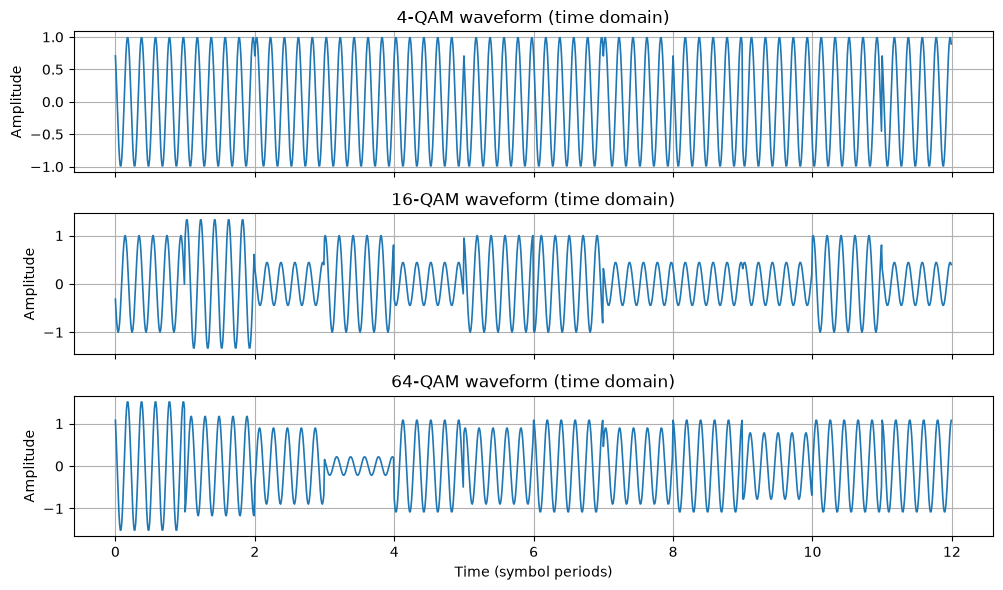

In [10]:
def qam_waveform(M=4, n_symbols=12, cycles_per_symbol=5, sps=100):
    """
    Generate a simple time-domain waveform for M-QAM.
    - M: constellation size
    - n_symbols: number of random symbols
    - cycles_per_symbol: carrier cycles during one symbol period
    - sps: samples per symbol
    """
    pts = qam_points(M)  # constellation
    bps = int(np.log2(M))

    # Random symbol sequence
    idx = np.random.randint(0, M, n_symbols)
    symbols = pts[idx]

    # Time base
    t = np.linspace(0, n_symbols, n_symbols*sps, endpoint=False)
    carrier = np.exp(1j * 2*np.pi*cycles_per_symbol*t)

    # Repeat each symbol for sps samples
    symbols_up = np.repeat(symbols, sps)

    # Modulate
    tx = np.real(symbols_up * carrier)

    return t, tx, idx, symbols

# --- Plot example waveforms ---
fig, axes = plt.subplots(3, 1, figsize=(10,6), sharex=True)

for ax, M in zip(axes, [4, 16, 64]):
    t, tx, idx, symbols = qam_waveform(M)
    ax.plot(t, tx, lw=1.2)
    ax.set_title(f"{M}-QAM waveform (time domain)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

axes[-1].set_xlabel("Time (symbol periods)")
plt.tight_layout()
plt.show()


#### 4.3.4 Bit Rate vs. Symbol Rate (Baud Rate)

The **symbol rate**, measured in baud, is the number of symbols transmitted per second. The **modulation bit rate** counts the channel-coded bits represented by those symbols each second. Because a symbol chosen from $M$ possible states carries $\log_2(M)$ bits, the rates are related by

$$
R_b = R_s \cdot \log_2(M)
$$

where $R_b$ is the modulation bit rate in bits per second, $R_s$ is the symbol rate in symbols per second, and $M$ is the constellation size. At the same symbol rate, QPSK carries two bits per symbol, 16-QAM carries four, and 64-QAM carries six. Increasing the modulation order therefore raises the bit rate without requiring more symbols per second.

The previous notebook introduced the channel-code rate $R_c$, which describes the proportion of coded bits that carries source information. When channel coding is used, the net information rate is

$$
R_{\text{information}}=R_cR_b=R_cR_s\log_2(M).
$$

A higher modulation order provides more bits per symbol, but it also requires more precise detection. When average transmit power is held fixed, adding constellation points reduces the distance between neighbouring states. Noise, interference, or distortion can then move a received symbol into the wrong decision region more easily. Maintaining a comparable error rate consequently requires a higher **signal-to-noise ratio (SNR)**.

This explains the trade-off behind adaptive modulation. A lower order, such as QPSK, provides greater tolerance to noise at the cost of a lower bit rate. A higher order, such as 64-QAM, can deliver more data when channel conditions support reliable detection. Adapting the modulation order to the measured channel quality allows a system to balance data rate and reliability. The exercises below explore this relationship using noisy constellations and a simplified switching rule.


----

### 4.4 Hands-On Exercises

<div class="alert alert-block alert-info">Fill in the responses and save this notebook. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>

**Why is QPSK suitable for operation at low SNR? Relate the answer to the separation between constellation points.**

Quadrature phase-shift keying (QPSK) has only 4 points, so they are far apart. Noise pushes the received point a bit away from where it should be. Because the points are far apart, it would have to be pushed very far to end up near a wrong point. So even with a lot of noise (low signal-to-noise ratio, SNR), the receiver can still tell which point was sent.

**Why does a higher SNR allow a higher QAM modulation order while maintaining reliable detection?**

A higher quadrature amplitude modulation (QAM) order has more points, so they are closer together. With a lot of noise, close points are easily mixed up. With a high SNR, there is only a little noise, so the received point stays very close to where it should be. The receiver can then still tell the close points apart.

**What is the trade-off between throughput and reliability? Give one example of a real technology that uses adaptive modulation to manage this trade-off.**  

More points per symbol means more bits per symbol, so data is sent faster (higher throughput). But the points are closer together, so errors happen more easily (lower reliability). Fewer points are slower, but safer. Example: mobile data on a smartphone (4G/5G). With full signal bars, the phone uses many points and downloads fast. With only one bar, it switches to fewer points: downloads are slower, but the connection still works.

**If the symbol rate is 1000 symbols/s, what is the modulation bit rate for QPSK, 16-QAM, and 64-QAM?**  

- $R_b = R_s \cdot \log_2(M)$
- $R_s = 1000$ symbols/s

| Modulation | $M$ | Bits per symbol $\log_2(M)$ | Bit rate $R_b$ |
|---|---|---|---|
| QPSK | 4 | 2 | $2000$ bit/s |
| 16-QAM | 16 | 4 | $4000$ bit/s |
| 64-QAM | 64 | 6 | $6000$ bit/s |

Here, $E_s/N_0$ is the ratio of average symbol energy to noise power spectral density. The slider expresses this ratio in dB; larger values mean less noise relative to the symbol energy.

**Run the cell below and observe how the received points form clouds around each ideal symbol as $E_s/N_0$ changes. Report an approximate $E_s/N_0$ value in dB at which the clouds visibly overlap for 16-QAM, and compare it with 4-QAM. Treat this as a visual estimate rather than a precise error-rate threshold.**  

- **16-QAM:** the clouds start to overlap at about $E_s/N_0 \approx 15$ dB.
- **4-QAM:** the clouds start to overlap at about $E_s/N_0 \approx 9$ dB.

4-QAM can handle more noise, because its 4 points are much farther apart than the 16 points of 16-QAM.


In [12]:
rng = np.random.default_rng(0)

def add_awgn(x, esn0_db):
    """Add complex AWGN to achieve target Es/N0 (dB). Assumes E[|x|^2]=1."""
    snr_linear = 10**(esn0_db/10)
    n0 = 1 / snr_linear
    noise = np.sqrt(n0/2) * (rng.standard_normal(x.size) + 1j*rng.standard_normal(x.size))
    return x + noise

def noisy_constellation(M=16, esn0_db=15.0, n_per_point=200):
    if not isinstance(n_per_point, (int, np.integer)) or n_per_point < 1:
        print("Choose a positive whole number of samples per constellation point.")
        return
    pts = qam_points(M)
    tx = np.repeat(pts, n_per_point)  # equal probability for each point
    rx = add_awgn(tx, esn0_db)
    
    plt.figure(figsize=(6,6))
    plt.scatter(rx.real, rx.imag, s=6, alpha=0.6, label='Received')
    plt.scatter(pts.real, pts.imag, s=60, marker='x', label='Ideal')
    lim = 1.4*np.max(np.abs(np.concatenate([pts.real, pts.imag])))
    plt.xlim(-lim, lim); plt.ylim(-lim, lim)
    plt.axhline(0, c='k', lw=0.6); plt.axvline(0, c='k', lw=0.6)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(True); plt.legend()
    plt.title(f"Noisy Constellation: {M}-QAM, Es/N0 = {esn0_db:.1f} dB")
    plt.xlabel("I"); plt.ylabel("Q")
    plt.show()

interact(
    noisy_constellation,
    M=Dropdown(options=[4,16,64,256], value=16, description='QAM'),
    esn0_db=FloatSlider(min=-5, max=30, step=1, value=15, description='Es/N0 (dB)'),
    n_per_point=IntSlider(min=1, max=1000, step=1, value=200,
                          description='Samples/point', continuous_update=False),
);

interactive(children=(Dropdown(description='QAM', index=1, options=(4, 16, 64, 256), value=16), FloatSlider(va…

**A 5G cellular connection can adapt between QPSK, 16-QAM, and 64-QAM according to the measured channel quality, such as the signal-to-interference-plus-noise ratio (SINR). Which modulation would generally be expected under good channel conditions, and which under poor channel conditions? Why?**  

- Good conditions (high SINR): 64-QAM. There is little noise, so even points that are close together can be told apart. Each symbol carries 6 bits, so data is sent fast.
- Poor conditions (low SINR): QPSK. There is a lot of noise, so the points must be far apart to avoid mix-ups. Each symbol carries only 2 bits, which is slower, but the connection stays reliable.

**OPTIONAL: Have all tasks in this notebook been read and understood? Are there any shortcomings, missing parts, or sections that should be improved?**

Please help the teaching team improve the notebook by identifying unclear tasks or explanations and suggesting improvements.

(answer here)
